BASE DE DATOS DE ESTUDIANTES
       Horas  Asistencia  Tareas      Nota  Resultado
0   7.490802          93      52  6.886098   Aprobado
1  19.014286          56      87  7.398952   Aprobado
2  14.639879          48      85  7.271917   Aprobado
3  11.973170          72      29  4.955634  Reprobado
4   3.120373          92      24  4.169061  Reprobado


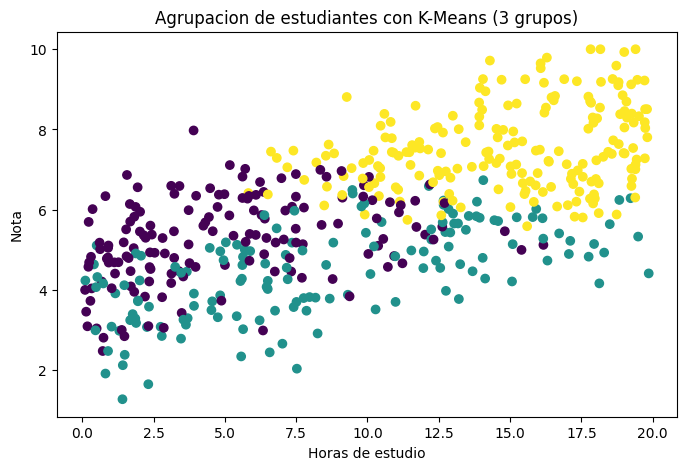

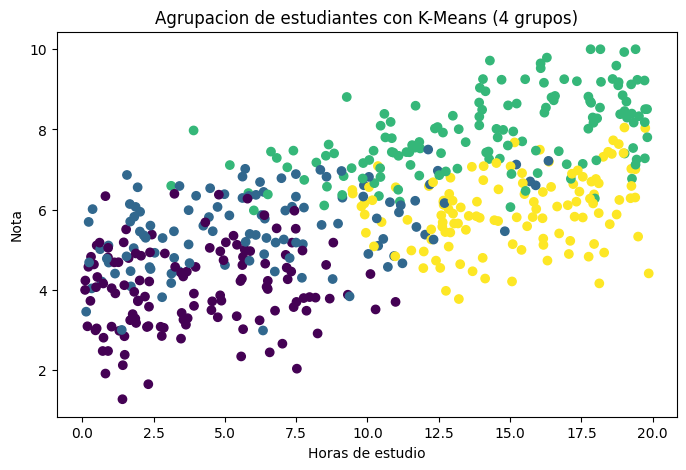


CARACTERISTICAS DE LOS 3 GRUPOS
   Horas  Asistencia  Tareas  Nota
0   5.03       82.18   57.59  5.26
1   8.46       51.84   43.20  4.47
2  14.89       72.71   71.36  7.54

CARACTERISTICAS DE LOS 4 GRUPOS
   Horas  Asistencia  Tareas  Nota
0   3.96       56.30   50.57  4.04
1   6.16       88.00   53.78  5.54
2  14.12       77.04   79.50  7.90
3  14.99       56.96   48.15  6.00
K = 1 | Exactitud: 78.40%
K = 3 | Exactitud: 78.40%
K = 5 | Exactitud: 80.00%
K = 7 | Exactitud: 80.00%
K = 11 | Exactitud: 80.00%
K = 15 | Exactitud: 81.60%
K = 21 | Exactitud: 80.80%

El mejor valor de K es: 15
Su exactitud es: 81.6 %

RESULTADOS SIN NORMALIZAR
K = 1 | Exactitud: 73.60%
K = 3 | Exactitud: 82.40%
K = 5 | Exactitud: 81.60%
K = 7 | Exactitud: 79.20%
K = 11 | Exactitud: 80.00%
K = 15 | Exactitud: 82.40%
K = 21 | Exactitud: 80.80%

COMPARACION DE RESULTADOS
    K  Con normalizacion  Sin normalizacion
0   1               78.4               73.6
1   3               78.4               82.4
2   5      

In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

np.random.seed(42)

estudiantes = 500

# datos
horas = np.random.uniform(0, 20, estudiantes)
asistencia = np.random.randint(40, 101, estudiantes)
tareas = np.random.randint(20, 101, estudiantes)


notas = (
    0.35 * (horas / 20 * 10) +
    0.30 * (asistencia / 100 * 10) +
    0.35 * (tareas / 100 * 10) +
    np.random.normal(0, 0.8, estudiantes)
)

notas = np.clip(notas, 0, 10)


datos = pd.DataFrame({
    "Horas": horas,
    "Asistencia": asistencia,
    "Tareas": tareas,
    "Nota": notas
})

# Clasificacion de estudiantes
datos["Resultado"] = np.where(
    datos["Nota"] >= 6,
    "Aprobado",
    "Reprobado"
)

print("BASE DE DATOS DE ESTUDIANTES")
print(datos.head())

# Agrupacion con KMEANS
caracteristicas = datos[["Horas", "Asistencia", "Tareas", "Nota"]]

escalador = StandardScaler()
caracteristicas_escaladas = escalador.fit_transform(caracteristicas)

# Agrupacion en 3 grupos
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
grupos3 = kmeans3.fit_predict(caracteristicas_escaladas)
datos["Grupo_3"] = grupos3

plt.figure(figsize=(8, 5))
plt.scatter(
    datos["Horas"],
    datos["Nota"],
    c=grupos3,
    cmap="viridis"
)
plt.xlabel("Horas de estudio")
plt.ylabel("Nota")
plt.title("Agrupacion de estudiantes con K-Means (3 grupos)")
plt.show()

# 4 grupos
kmeans4 = KMeans(n_clusters=4, random_state=42, n_init=10)
grupos4 = kmeans4.fit_predict(caracteristicas_escaladas)
datos["Grupo_4"] = grupos4

plt.figure(figsize=(8, 5))
plt.scatter(
    datos["Horas"],
    datos["Nota"],
    c=grupos4,
    cmap="viridis"
)
plt.xlabel("Horas de estudio")
plt.ylabel("Nota")
plt.title("Agrupacion de estudiantes con K-Means (4 grupos)")
plt.show()

# Caracteristicas
print("\nCARACTERISTICAS DE LOS 3 GRUPOS")
centros3 = escalador.inverse_transform(kmeans3.cluster_centers_)

print(pd.DataFrame(
    centros3,
    columns=["Horas", "Asistencia", "Tareas", "Nota"]
).round(2))

print("\nCARACTERISTICAS DE LOS 4 GRUPOS")
centros4 = escalador.inverse_transform(kmeans4.cluster_centers_)

print(pd.DataFrame(
    centros4,
    columns=["Horas", "Asistencia", "Tareas", "Nota"]
).round(2))

# Prediccion

X = datos[["Horas", "Asistencia", "Tareas"]]
y = datos["Resultado"]

# Division
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Normalizacion
escalador_knn = StandardScaler()

X_entrenamiento_escalado = escalador_knn.fit_transform(X_entrenamiento)
X_prueba_escalado = escalador_knn.transform(X_prueba)

# Prueba de valores
valores_k = [1, 3, 5, 7, 11, 15, 21]
resultados = {}

for k in valores_k:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_entrenamiento_escalado, y_entrenamiento)

    predicciones = modelo.predict(X_prueba_escalado)

    exactitud = accuracy_score(y_prueba, predicciones)
    resultados[k] = exactitud

    print(f"K = {k} | Exactitud: {exactitud * 100:.2f}%")

# Identificar valor de k
mejor_k = max(resultados, key=resultados.get)

print("\nEl mejor valor de K es:", mejor_k)
print("Su exactitud es:", resultados[mejor_k] * 100, "%")

# Comparacion
print("\nRESULTADOS SIN NORMALIZAR")

resultados_sin_normalizar = {}

for k in valores_k:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_entrenamiento, y_entrenamiento)

    predicciones = modelo.predict(X_prueba)

    exactitud = accuracy_score(y_prueba, predicciones)
    resultados_sin_normalizar[k] = exactitud

    print(f"K = {k} | Exactitud: {exactitud * 100:.2f}%")


comparacion = pd.DataFrame({
    "K": valores_k,
    "Con normalizacion": [resultados[k] * 100 for k in valores_k],
    "Sin normalizacion": [resultados_sin_normalizar[k] * 100 for k in valores_k]
})

print("\nCOMPARACION DE RESULTADOS")
print(comparacion.round(2))

# nuevo estudiante
mejor_modelo = KNeighborsClassifier(n_neighbors=mejor_k)

mejor_modelo.fit(X_entrenamiento_escalado, y_entrenamiento)

nuevo_estudiante = pd.DataFrame({
    "Horas": [4],
    "Asistencia": [55],
    "Tareas": [50]
})

nuevo_estudiante_escalado = escalador_knn.transform(nuevo_estudiante)

prediccion = mejor_modelo.predict(nuevo_estudiante_escalado)

print("\nPREDICCION DEL NUEVO ESTUDIANTE")
print("Resultado del estudiante:", prediccion[0])
